# CODE-M · Day 3 · Hands-on B
## Essential genes and strain design

> **Complete version.** Every task is solved and the outputs are included, for reference and for instructors. Attendees work in the *student* version.

Two questions that make metabolic models useful outside the computer: **which genes can a cell not live without?** (drug targets, and a test of the model against knockout collections) and **which genes can you delete to make it produce something?** (metabolic engineering).

You'll use **E. coli core**, small enough to test every gene and every pair of genes in seconds, and **iML1515**, the genome-scale model of *E. coli* K-12 MG1655 you met on Day 2.

| Section | Model | Time |
|---|---|---|
| 0 · Setup | | 2 min |
| 1 · Essential genes depend on the conditions | E. coli core | 10 min |
| 2 · Genome scale: minimal and rich medium | iML1515 | 8 min |
| 3 · Synthetic lethality | E. coli core | 8 min |
| 4 · Production envelopes | E. coli core | 10 min |
| 5 · Design a producer strain | E. coli core | 18 min |

**How to use this notebook**
- Run the cells in order with **Shift + Enter**.
- ✍️ marks a task for you: replace each `...` with your code.
- ✅ marks a checkpoint: if it prints a green tick, carry on. If it raises an error, the message tells you what to look at.
- 💬 marks a question to discuss with your neighbour.
- Short of time? §2 and the extension at the end are optional.

## 0 · Setup  ·  2 min

In [1]:
import itertools
import logging
import warnings
from collections import Counter

warnings.filterwarnings("ignore")
logging.getLogger("cobra").setLevel(logging.ERROR)      # keep the output tidy

import pandas as pd
import matplotlib.pyplot as plt
import cobra
from cobra.flux_analysis import (single_gene_deletion, double_gene_deletion, pfba,
                                 flux_variability_analysis, production_envelope)
from day3_helpers import MODELS

cobra.Configuration().processes = 1
print("cobrapy", cobra.__version__, "| LP solver:", cobra.Configuration().solver.__name__.split("_")[0].split(".")[-1])

cobrapy 0.32.1 | LP solver: glpk


## 1 · Essential genes depend on the conditions  ·  10 min

A gene is **essential** (in a model) if deleting it stops growth. cobrapy's `single_gene_deletion()` deletes each gene in turn, switches off every reaction whose gene rule then fails, and re-runs FBA.

In [2]:
ecoli = cobra.io.read_sbml_model(str(MODELS / "e_coli_core.xml"))
BIO = "BIOMASS_Ecoli_core_w_GAM"
names = {g.id: g.name for g in ecoli.genes}
print(f"{len(ecoli.genes)} genes; wild-type growth {ecoli.slim_optimize():.3f} per hour")

137 genes; wild-type growth 0.874 per hour


One "gene", `s0001`, is not a gene: the model uses it for spontaneous reactions such as the diffusion of oxygen and ammonium across the membrane. We leave it out.

✍️ Complete `essential_genes()`: keep the rows of `result` whose growth is below `threshold` times the wild-type growth. Growth is `NaN` when the problem has no solution, so `.fillna(0)` treats it as zero.

In [3]:
def essential_genes(model, threshold=0.01):
    """Genes whose deletion drops growth below `threshold` x wild type (s0001 excluded)."""
    wild_type = model.slim_optimize()
    result = single_gene_deletion(model)
    result["gene"] = [next(iter(ids)) for ids in result["ids"]]
    lethal = result[result["growth"].fillna(0) < threshold * wild_type]
    return set(lethal["gene"]) - {"s0001"}


ess_aerobic = essential_genes(ecoli)
with ecoli:
    ecoli.reactions.EX_o2_e.lower_bound = 0                 # no oxygen
    ess_anaerobic = essential_genes(ecoli)

pd.DataFrame([(g, names[g], ", ".join(r.id for r in ecoli.genes.get_by_id(g).reactions),
               "yes" if g in ess_aerobic else "no", "yes" if g in ess_anaerobic else "no")
              for g in sorted(ess_aerobic | ess_anaerobic)],
             columns=["gene", "name", "reactions", "essential with O2", "essential without O2"])

,gene,name,reactions,essential with O2,essential without O2
0,b0720,gltA,CS,yes,yes
1,b1136,icd,ICDHyr,yes,yes
2,b1779,gapA,GAPD,yes,yes
3,b2415,ptsH,"GLCpts, FRUpts2",yes,yes
4,b2416,ptsI,"GLCpts, FRUpts2",yes,yes
5,b2779,eno,ENO,yes,yes
6,b2926,pgk,PGK,yes,yes
7,b3919,tpiA,TPI,no,yes
8,b3956,ppc,PPC,no,yes
9,b4025,pgi,PGI,no,yes


In [4]:
# ✅ Checkpoint
conditional = sorted(names[g] for g in ess_anaerobic - ess_aerobic)
assert conditional == ["pgi", "ppc", "tpiA"], f"expected pgi, ppc and tpiA to be essential only without oxygen, got {conditional}"
print(f"✅ {len(ess_aerobic)} essential genes with oxygen, {len(ess_anaerobic)} without; essential only without oxygen: {conditional}")

✅ 7 essential genes with oxygen, 10 without; essential only without oxygen: ['pgi', 'ppc', 'tpiA']


💬 Why do *pgi*, *tpiA* and *ppc* become essential only without oxygen? Delete each one **with** oxygen and see how the cell copes: which reactions take over?

In [5]:
watch = ["PGI", "G6PDH2r", "GND", "TPI", "NADTRHD", "NADH16", "CYTBD", "PPC", "ICL", "MALS"]
reroute = {}
for gene in ["b4025", "b3919", "b3956"]:                     # pgi, tpiA, ppc
    with ecoli:
        ecoli.genes.get_by_id(gene).knock_out()
        reroute[f"Δ{names[gene]} (with O2)"] = pfba(ecoli).fluxes[watch + [BIO]]
reroute["wild type (with O2)"] = pfba(ecoli).fluxes[watch + [BIO]]
pd.DataFrame(reroute).round(2)

,Δpgi (with O2),ΔtpiA (with O2),Δppc (with O2),wild type (with O2)
PGI,0.00,-18.04,3.43,4.86
G6PDH2r,9.82,27.90,6.40,4.96
GND,9.82,27.90,6.40,4.96
TPI,5.87,0.00,7.00,7.48
NADTRHD,8.45,43.73,0.00,0.00
NADH16,40.93,55.05,39.24,38.53
CYTBD,44.54,55.05,43.88,43.60
PPC,2.47,2.02,0.00,2.50
ICL,0.00,0.00,2.50,0.00
MALS,0.00,0.00,2.50,0.00


<details><summary><b>Answer</b> (click to expand)</summary>

Without *pgi* or *tpiA*, glucose detours through the oxidative pentose-phosphate pathway (`G6PDH2r`, `GND`), which makes far more NADPH than the cell needs. The model converts the extra NADPH into NADH with a transhydrogenase (`NADTRHD`) and reoxidises it in the respiratory chain (`NADH16`, `CYTBD`). Without oxygen there is no respiratory chain to dispose of that NADH, so the detour is closed and the deletion is lethal. Without *ppc*, the aerobic cell refills oxaloacetate through the glyoxylate shunt (`ICL`, `MALS`); without oxygen that route doesn't work in the model, and PEP carboxylase becomes the only way to make oxaloacetate. Essentiality is a property of a gene **and** a condition.

</details>

## 2 · Genome scale: minimal and rich medium  ·  8 min  (optional)

Now the 1,516 genes of iML1515: first on its default minimal glucose medium, then on a "rich" medium where every compound the model can take up is available (10 mmol/gDW/h each). Each scan takes about 10–15 seconds.

✍️ Build `rich`: start from the default medium and add every other exchange reaction with an uptake of 10. (`dict.setdefault(key, value)` adds a key only if it isn't there yet.)

In [6]:
iml = cobra.io.read_sbml_model(str(MODELS / "iML1515.xml"))
ess_minimal = essential_genes(iml)

rich = dict(iml.medium)
for ex in iml.exchanges:
    rich.setdefault(ex.id, 10)
with iml:
    iml.medium = rich
    ess_rich = essential_genes(iml)
print(f"essential genes: {len(ess_minimal)} on minimal medium, {len(ess_rich)} on rich medium")

essential genes: 195 on minimal medium, 87 on rich medium


In [7]:
# ✅ Checkpoint
assert len(rich) > 300 and len(ess_rich) < len(ess_minimal), "the rich medium should open every exchange reaction"
print("✅ Genome-scale essentiality done")

✅ Genome-scale essentiality done


Which genes are essential on minimal medium but not on rich medium? Gene names usually start with a three-letter code for their pathway (`arg`: arginine, `trp`: tryptophan, `bio`: biotin …).

108 genes essential only on minimal medium


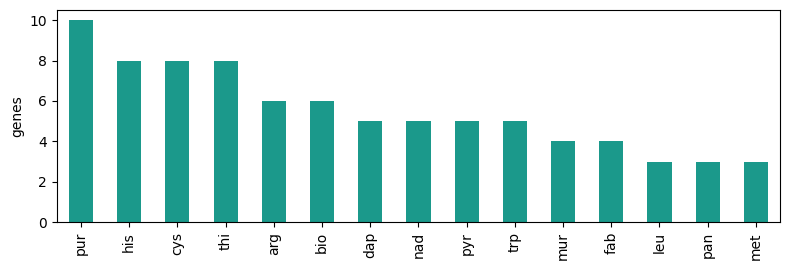

In [8]:
iml_names = {g.id: g.name for g in iml.genes}
only_minimal = sorted(iml_names[g] for g in ess_minimal - ess_rich)
print(len(only_minimal), "genes essential only on minimal medium")
pd.Series(Counter(name[:3] for name in only_minimal)).sort_values(ascending=False).head(15).plot.bar(figsize=(8, 2.8), color="#1B998B")
plt.ylabel("genes")
plt.tight_layout()
plt.show()

💬 What do these genes have in common? How would you check the model's essentiality predictions in the lab?

<details><summary><b>Answer</b> (click to expand)</summary>

They are biosynthesis genes for nucleotides (`pur`, `pyr`), amino acids (`his`, `cys`, `arg`, `trp` …) and vitamins or cofactors (`thi`, `bio`, `nad`, `pan`): on minimal medium the cell must make these compounds itself, while the rich medium provides them, so the same deletion goes from lethal to harmless. Even some cell-wall (`mur`) and fatty-acid (`fab`) genes drop out, because our 'rich' medium offers everything the model can take up, which no real medium does. The classic test is a genome-wide knockout collection, such as the Keio collection of *E. coli* single-gene deletions (Baba et al., Mol. Syst. Biol. 2006), grown on defined media, or transposon sequencing (Tn-seq); iML1515 was checked against data of this kind.

</details>

## 3 · Synthetic lethality  ·  8 min

Two genes are **synthetic lethal** if the cell survives without either one, but not without both. `double_gene_deletion()` tests every pair of the 137 genes of E. coli core: about 9,400 FBA problems, which take a few seconds.

✍️ Complete the condition: a pair is synthetic lethal if the double deletion grows below 1% of the wild type **and** each single deletion grows at least 1% of the wild type.

In [9]:
wild_type = ecoli.slim_optimize()
single = single_gene_deletion(ecoli)
single_growth = {next(iter(ids)): g for ids, g in zip(single["ids"], single["growth"].fillna(0))}
double = double_gene_deletion(ecoli)

pairs = []
for ids, growth in zip(double["ids"], double["growth"].fillna(0)):
    if len(ids) != 2 or "s0001" in ids:
        continue
    a, b = sorted(ids)
    if growth < 0.01 * wild_type and single_growth[a] >= 0.01 * wild_type and single_growth[b] >= 0.01 * wild_type:
        pairs.append((names[a], names[b], ", ".join(r.id for r in ecoli.genes.get_by_id(a).reactions),
                      ", ".join(r.id for r in ecoli.genes.get_by_id(b).reactions)))
synthetic_lethal = pd.DataFrame(pairs, columns=["gene 1", "gene 2", "reactions of gene 1", "reactions of gene 2"])
print(len(synthetic_lethal), "synthetic lethal pairs")
synthetic_lethal.head(12)

49 synthetic lethal pairs


,gene 1,gene 2,reactions of gene 1,reactions of gene 2
0,nuoC,tpiA,NADH16,TPI
1,nuoB,tpiA,NADH16,TPI
2,sdhD,ppc,SUCDi,PPC
3,gnd,tpiA,GND,TPI
4,nuoJ,tpiA,NADH16,TPI
5,nuoK,tpiA,NADH16,TPI
6,nuoL,pgi,NADH16,PGI
7,sdhB,ppc,SUCDi,PPC
8,nuoA,pgi,NADH16,PGI
9,nuoK,pgi,NADH16,PGI


In [10]:
# ✅ Checkpoint
found = {tuple(sorted(p)) for p in synthetic_lethal[["gene 1", "gene 2"]].itertuples(index=False)}
assert ("gdhA", "gltB") in found, "gdhA + gltB should be synthetic lethal"
assert all(single_growth[g.id] >= 0.01 * wild_type for g in ecoli.genes if g.name in set(synthetic_lethal["gene 1"])), "single deletions must be viable"
print("✅ Synthetic lethal pairs found")

✅ Synthetic lethal pairs found


💬 Look at *gdhA* and *gltB*: what do their reactions do, and why can the cell lose either but not both? Why do drug developers care about synthetic lethality?

In [11]:
for rid in ["GLUDy", "GLUSy", "GLNS"]:
    r = ecoli.reactions.get_by_id(rid)
    print(f"{rid:6s} {r.name}  [{r.gene_reaction_rule}]\n       {r.build_reaction_string(use_metabolite_names=True)}")

GLUDy  Glutamate dehydrogenase (NADP)  [b1761]
       L-Glutamate + H2O H2O + Nicotinamide adenine dinucleotide phosphate <=> 2-Oxoglutarate + H+ + Nicotinamide adenine dinucleotide phosphate - reduced + Ammonium
GLUSy  Glutamate synthase (NADPH)  [b3212 and b3213]
       2-Oxoglutarate + L-Glutamine + H+ + Nicotinamide adenine dinucleotide phosphate - reduced --> 2.0 L-Glutamate + Nicotinamide adenine dinucleotide phosphate
GLNS   Glutamine synthetase  [b3870 or b1297]
       ATP C10H12N5O13P3 + L-Glutamate + Ammonium --> ADP C10H12N5O10P2 + L-Glutamine + H+ + Phosphate


<details><summary><b>Answer</b> (click to expand)</summary>

Both make glutamate from ammonium, the cell's entry point for nitrogen. Glutamate dehydrogenase (*gdhA*, `GLUDy`) does it in one step; glutamine synthetase plus glutamate synthase (`GLNS` then *gltB*/*gltD*, `GLUSy`) does it in two. Either route is enough, so each single deletion is harmless, but without both the cell can't assimilate nitrogen. Some pairs in the table are simpler: *puuA* and *glnA*, or *pitA* and *pitB*, are isozymes of the same reaction, joined by `or` in its gene rule. Synthetic lethality is how combination therapies are designed: a drug that hits gene B kills only cells already missing gene A. The best-known example is PARP inhibitors, which kill cancer cells lacking functional BRCA genes.

</details>

## 4 · Production envelopes  ·  10 min

A **production envelope** shows the minimum and maximum production of a compound at each growth rate. It tells you how much product the network *can* make, and whether growth *forces* it to make any.

✍️ Complete `envelope()`: call `production_envelope(model, [BIO], objective=product, points=20)` inside the `with` block.

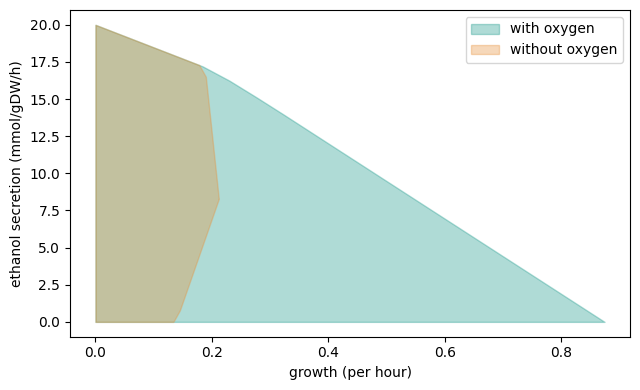

In [12]:
def envelope(model, product, o2):
    with model:
        model.reactions.EX_o2_e.lower_bound = -o2
        return production_envelope(model, [BIO], objective=product, points=20)


fig, ax = plt.subplots(figsize=(6.5, 4))
for o2, colour, label in [(1000, "#1B998B", "with oxygen"), (0, "#E8913A", "without oxygen")]:
    env = envelope(ecoli, "EX_etoh_e", o2)
    ax.fill_between(env[BIO], env.flux_minimum, env.flux_maximum, alpha=0.35, color=colour, label=label)
ax.set_xlabel("growth (per hour)")
ax.set_ylabel("ethanol secretion (mmol/gDW/h)")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# ✅ Checkpoint
anaerobic_env = envelope(ecoli, "EX_etoh_e", 0)
top = anaerobic_env.loc[anaerobic_env[BIO].idxmax()]
assert top.flux_minimum > 5, "without oxygen, ethanol should be forced at maximum growth"
print(f"✅ Without oxygen, at maximum growth ({top[BIO]:.2f} per hour) the cell must make at least {top.flux_minimum:.1f} mmol ethanol/gDW/h")

✅ Without oxygen, at maximum growth (0.21 per hour) the cell must make at least 8.3 mmol ethanol/gDW/h


💬 Read the two envelopes. How much ethanol can 10 mmol of glucose give at most? With oxygen, does growth force the cell to make any ethanol? And without oxygen?

<details><summary><b>Answer</b> (click to expand)</summary>

At zero growth the network can turn 10 glucose into 20 ethanol (2 per glucose), in both conditions. With oxygen, the minimum is zero at every growth rate: ethanol is possible but never necessary. Without oxygen, the minimum rises with growth, and at maximum growth the cell **must** make about 8.3 ethanol: production is **growth-coupled**, because fermenting is the only way to regenerate NAD⁺ and make ATP. Growth coupling is what metabolic engineers aim for: a strain that grows best when it makes the most product keeps making it, generation after generation.

</details>

## 5 · Design a producer strain  ·  18 min

Goal: an anaerobic E. coli strain that is **forced** to make more ethanol. We'll judge a design by two numbers: its maximum growth, and the **guaranteed** ethanol at that growth (the FVA minimum of the ethanol exchange at 99.9% of maximum growth). The wild type grows at 0.21 per hour and is guaranteed to make about 8.3 ethanol.

✍️ Complete `evaluate()`: after the knockouts, run FVA on the product only (`reaction_list=[product]`) with `fraction_of_optimum=0.999`, and return its minimum and maximum.

In [14]:
def evaluate(model, knockouts, product, o2=0):
    """Maximum growth and the product range at (almost) maximum growth, after knocking out `knockouts`."""
    with model:
        model.reactions.EX_o2_e.lower_bound = -o2
        for rid in knockouts:
            model.reactions.get_by_id(rid).knock_out()
        growth = model.slim_optimize(error_value=0)
        if growth < 0.01:
            return {"growth": 0.0, "min product": 0.0, "max product": 0.0}
        r = flux_variability_analysis(model, reaction_list=[product], fraction_of_optimum=0.999).loc[product]
        return {"growth": round(growth, 3), "min product": round(r.minimum, 2), "max product": round(r.maximum, 2)}


evaluate(ecoli, [], "EX_etoh_e")

{'growth': 0.212,
 'min product': np.float64(8.26),
 'max product': np.float64(8.36)}

In [15]:
# ✅ Checkpoint
wt = evaluate(ecoli, [], "EX_etoh_e")
assert abs(wt["growth"] - 0.212) < 0.01 and 7 < wt["min product"] < 9, "check the FVA call in evaluate()"
print("✅ evaluate() works")

✅ evaluate() works


First, every single knockout from a list of candidate reactions in central metabolism:

In [16]:
CANDIDATES = ["LDH_D", "ACKr", "PTAr", "ACt2r", "FRD7", "PFL", "PDH", "ME1", "ME2", "PPC", "PPCK",
              "SUCDi", "FUM", "MDH", "THD2", "GLUDy", "G6PDH2r", "PGI", "D_LACt2", "FORt"]
singles = pd.DataFrame({rid: evaluate(ecoli, [rid], "EX_etoh_e") for rid in CANDIDATES}).T
singles.sort_values(["min product", "growth"], ascending=False, kind="mergesort").head(8)

,growth,min product,max product
ACKr,0.189,16.52,16.65
PTAr,0.189,16.52,16.65
ACt2r,0.189,16.52,16.65
PFL,0.180,16.52,16.59
FORt,0.180,16.52,16.59
THD2,0.208,9.77,9.87
GLUDy,0.200,8.35,8.45
LDH_D,0.212,8.26,8.36


Now every combination of up to three knockouts, about 1,350 designs, in a few seconds. We keep designs that still grow at 0.05 per hour or more, and rank them by guaranteed ethanol.

In [17]:
designs = []
for k in (1, 2, 3):
    for kos in itertools.combinations(CANDIDATES, k):
        result = evaluate(ecoli, kos, "EX_etoh_e")
        if result["growth"] >= 0.05:
            designs.append({"knockouts": " + ".join(kos), "n": k, **result})
designs = pd.DataFrame(designs).sort_values(["min product", "growth"], ascending=False, kind="mergesort")
print(len(designs), "viable designs")
designs.head(10)

867

 viable designs


,knockouts,n,growth,min product,max product
394,ACKr + THD2 + G6PDH2r,3,0.171,17.34,17.40
491,PTAr + THD2 + G6PDH2r,3,0.171,17.34,17.40
574,ACt2r + THD2 + G6PDH2r,3,0.171,17.34,17.40
397,ACKr + GLUDy + G6PDH2r,3,0.177,17.24,17.31
494,PTAr + GLUDy + G6PDH2r,3,0.177,17.24,17.31
577,ACt2r + GLUDy + G6PDH2r,3,0.177,17.24,17.31
176,LDH_D + ACKr + G6PDH2r,3,0.188,17.12,17.15
191,LDH_D + PTAr + G6PDH2r,3,0.188,17.12,17.15
205,LDH_D + ACt2r + G6PDH2r,3,0.188,17.12,17.15
400,ACKr + G6PDH2r + D_LACt2,3,0.188,17.12,17.15


Compare the envelopes of the wild type, the best single knockout and the best triple.

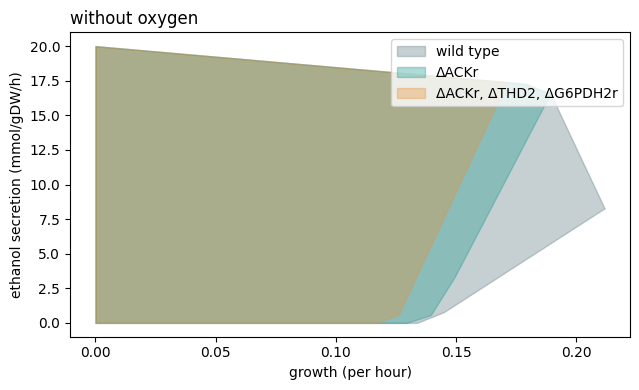

In [18]:
best_single = designs[designs.n == 1].iloc[0].knockouts.split(" + ")
best_triple = designs[designs.n == 3].iloc[0].knockouts.split(" + ")
fig, ax = plt.subplots(figsize=(6.5, 4))
for kos, colour, label in [([], "#5C7A82", "wild type"), (best_single, "#1B998B", "Δ" + best_single[0]),
                           (best_triple, "#E8913A", "Δ" + ", Δ".join(best_triple))]:
    with ecoli:
        for rid in kos:
            ecoli.reactions.get_by_id(rid).knock_out()
        env = envelope(ecoli, "EX_etoh_e", 0)
    ax.fill_between(env[BIO], env.flux_minimum, env.flux_maximum, alpha=0.35, color=colour, label=label)
ax.set_xlabel("growth (per hour)")
ax.set_ylabel("ethanol secretion (mmol/gDW/h)")
ax.set_title("without oxygen", loc="left")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

A reaction knockout is not a gene knockout. ✍️ Print the gene rules of the reactions in the best single and best triple designs, with gene names, to see what you would actually have to delete in the lab.

In [19]:
for rid in sorted(set(best_single + best_triple)):
    r = ecoli.reactions.get_by_id(rid)
    print(f"{rid:8s} {r.name:40s} {r.gene_reaction_rule:30s} -> {', '.join(sorted(g.name for g in r.genes))}")

ACKr     Acetate kinase                           b3115 or b2296 or b1849        -> ackA, purT, tdcD
G6PDH2r  Glucose 6-phosphate dehydrogenase        b1852                          -> zwf
THD2     NAD(P) transhydrogenase                  b1602 and b1603                -> pntA, pntB


💬 Would you build the best triple, or the best single knockout? What does the model not know that could make the design fail?

<details><summary><b>Answer</b> (click to expand)</summary>

Knocking out acetate kinase (`ACKr`) or phosphotransacetylase (`PTAr`) alone doubles the guaranteed ethanol, from about 8.3 to 16.5 mmol/gDW/h, while growth drops only from 0.21 to 0.19: the cell loses its acetate route and must ferment to ethanol instead. The best triple adds about 0.8 more ethanol (17.3, close to the maximum of 20) at the cost of more growth (0.17) and two more deletions. In the lab the single design is the obvious first step, and in fact *pta* and *ackA* deletions are classic in ethanol-producing E. coli. Note the gene rules: removing `ACKr` means deleting *ackA*, *tdcD* and *purT*, because any of them can do the job; removing `PTAr` means deleting *pta* and *eutD*. What the model doesn't know: regulation (a deleted gene's isozyme may be switched on, or a pathway switched off), kinetics and enzyme levels, toxicity of the product, and genes that are not in the model at all. Tools such as OptKnock (Burgard et al., Biotechnol. Bioeng. 2003), cameo and MEWpy search much larger design spaces in genome-scale models with the same logic.

</details>

### Extension (if you finish early): an acetate producer with oxygen

With oxygen, the wild type makes no acetate at maximum growth. ✍️ Rerun the search for `EX_ac_e` with `o2=1000`. Which pairs of knockouts force acetate secretion?

In [20]:
acetate = []
for k in (1, 2):
    for kos in itertools.combinations(CANDIDATES, k):
        result = evaluate(ecoli, kos, "EX_ac_e", o2=1000)
        if result["growth"] >= 0.05:
            acetate.append({"knockouts": " + ".join(kos), "n": k, **result})
pd.DataFrame(acetate).sort_values(["min product", "growth"], ascending=False).head(8)

,knockouts,n,growth,min product,max product
173,SUCDi + G6PDH2r,2,0.617,10.47,10.63
180,FUM + G6PDH2r,2,0.617,10.47,10.63
174,SUCDi + PGI,2,0.739,5.37,5.49
181,FUM + PGI,2,0.739,5.37,5.49
0,LDH_D,1,0.874,0.00,0.04
1,ACKr,1,0.874,0.00,0.00
2,PTAr,1,0.874,0.00,0.00
3,ACt2r,1,0.874,0.00,0.00


<details><summary><b>Answer</b> (click to expand)</summary>

No single knockout forces acetate, but several pairs do: deleting succinate dehydrogenase (`SUCDi`, or fumarase `FUM`) together with glucose-6-phosphate dehydrogenase (`G6PDH2r`) forces about 10.5 mmol acetate/gDW/h at a growth of 0.62. Both deletions limit how the cell can reoxidise NADH and make NADPH, so it overflows to acetate to balance its redox. Acetate is usually an unwanted by-product in E. coli bioprocesses; the same search, run the other way round, tells you which deletions to avoid.

</details>

## Recap

| Question | Method | What you found |
|---|---|---|
| Which genes are essential? | `single_gene_deletion` | Depends on the conditions: *pgi*, *tpiA*, *ppc* only without oxygen; about 110 iML1515 genes only on minimal medium |
| Which pairs are essential? | `double_gene_deletion` | Synthetic lethal pairs such as *gdhA* + *gltB*: two routes to the same product |
| How much product is possible, and is it forced? | Production envelope | Up to 2 ethanol per glucose; growth-coupled only without oxygen |
| Which knockouts force production? | FVA minimum at maximum growth, searched over designs | Δ*ackA*/*pta* doubles guaranteed ethanol |

**After lunch**: omics integration (13:00), where gene expression data constrain these same models, and COMETS (14:00), where several models share one environment.